Por favor, sube el archivo CSV de la EVA:


Saving Evaluaciones_Agropecuarias_Municipales_–_EVA._2019_-_2025._Base_Agrícola_20261122.csv to Evaluaciones_Agropecuarias_Municipales_–_EVA._2019_-_2025._Base_Agrícola_20261122 (1).csv

¡Archivo cargado! Dimensiones originales: (166732, 18)

--- INICIANDO PREPROCESAMIENTO ---
Registros después de limpiar nulos: 166732
Registros después de quitar atípicos extremos: 160490
Se tomó una muestra aleatoria para evitar el colapso de RAM: 5000 registros

--- EJECUTANDO K-MEANS ---


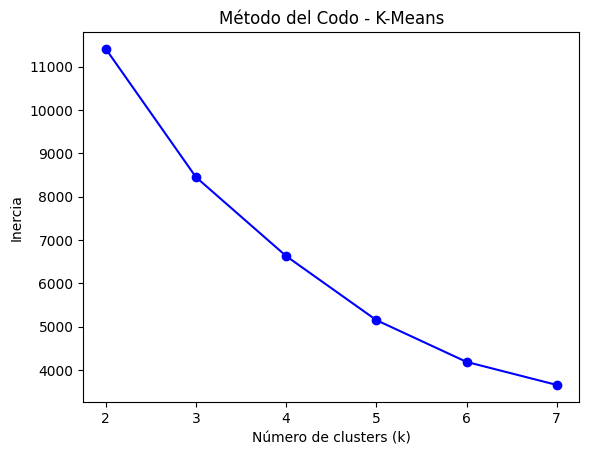

K-Means (k=4) -> Silhouette: 0.6192 | DB: 0.9190 | CH: 3358.07

--- EJECUTANDO DBSCAN ---
DBSCAN (eps=0.8) -> Silhouette: 0.7349 | Ruido: 3.46%


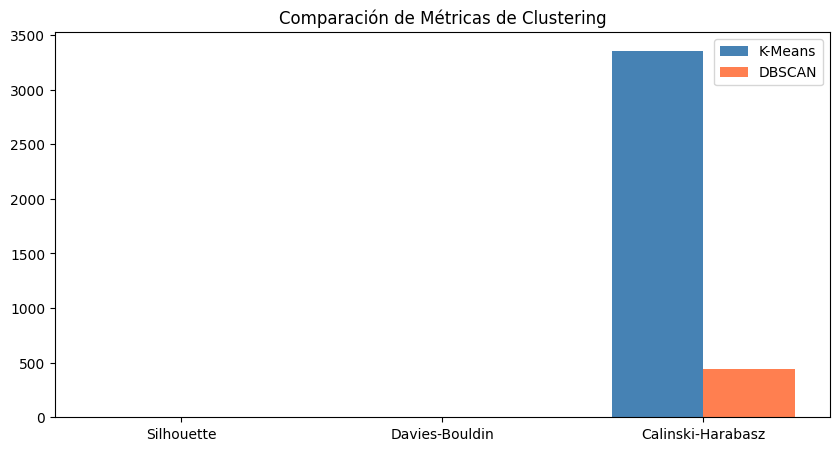

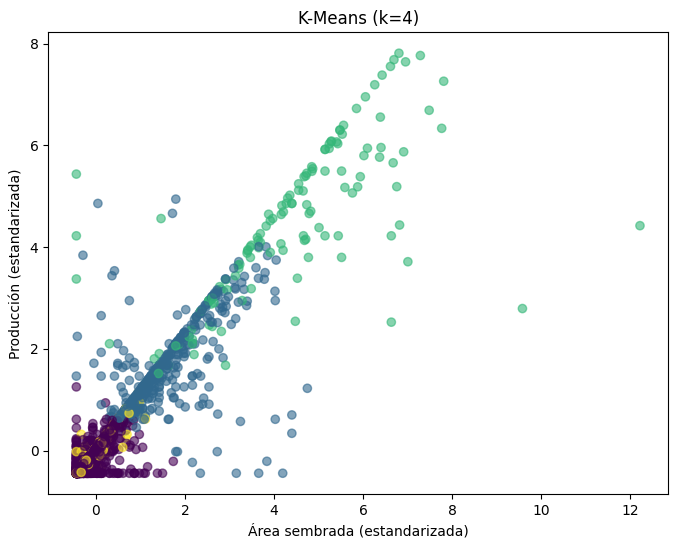

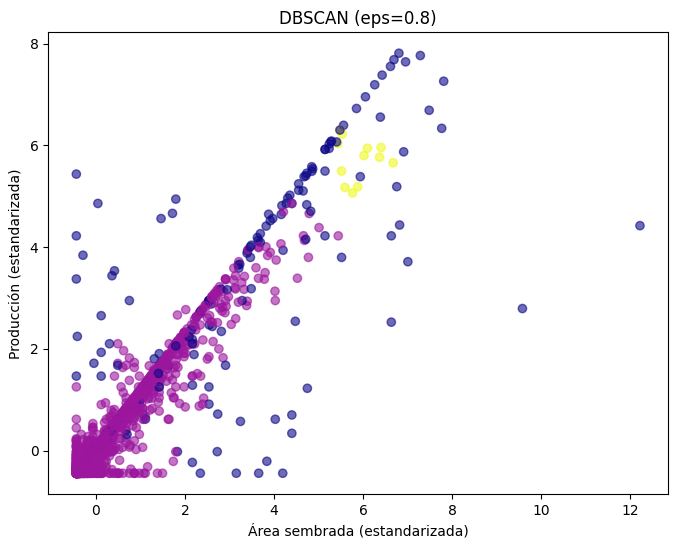


✅ ¡Proceso terminado con éxito!.


In [ ]:
# ============================================================
# PROYECTO FINAL: CLUSTERING NO SUPERVISADO - EVA COLOMBIA (CORREGIDO)
# ============================================================

!pip install pandas numpy scikit-learn matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import time
import json
import warnings
warnings.filterwarnings('ignore')

# 1. CARGA DE DATOS
from google.colab import files
print("Por favor, sube el archivo CSV de la EVA:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

try:
    df = pd.read_csv(filename, sep=',', encoding='utf-8')
except:
    df = pd.read_csv(filename, sep=';', encoding='latin-1')

print(f"\n¡Archivo cargado! Dimensiones originales: {df.shape}")

# 2. PREPROCESAMIENTO (FASE 4)
print("\n--- INICIANDO PREPROCESAMIENTO ---")

columnas_numericas = ['Área sembrada', 'Área cosechada', 'Producción', 'Rendimiento']

def limpiar_numero(x):
    if pd.isna(x): return np.nan
    x = str(x).replace('.', '').replace(',', '.')
    try:
        return float(x)
    except:
        return np.nan

for col in columnas_numericas:
    df[col] = df[col].apply(limpiar_numero)

# Eliminamos filas con nulos
df_clean = df.dropna(subset=columnas_numericas).copy()
print(f"Registros después de limpiar nulos: {df_clean.shape[0]}")

# Filtro de outliers (99%)
for col in columnas_numericas:
    limite_superior = df_clean[col].quantile(0.99)
    df_clean = df_clean[df_clean[col] <= limite_superior]

print(f"Registros después de quitar atípicos extremos: {df_clean.shape[0]}")

# Se realiza una toma de 5000 registros por falta de ram
if len(df_clean) > 5000:
    df_clean = df_clean.sample(n=5000, random_state=42)
    print(f"Se tomó una muestra aleatoria para evitar el colapso de RAM: {df_clean.shape[0]} registros")

# Seleccionamos las variables y estandarizamos
X = df_clean[columnas_numericas]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. K-MEANS
print("\n--- EJECUTANDO K-MEANS ---")
inertias = []
K_range = range(2, 8)
for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)

plt.figure()
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia')
plt.title('Método del Codo - K-Means')
plt.savefig('elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()

k_optimo = 4
start_time = time.time()
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_time = time.time() - start_time

kmeans_sil = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

print(f"K-Means (k={k_optimo}) -> Silhouette: {kmeans_sil:.4f} | DB: {kmeans_db:.4f} | CH: {kmeans_ch:.2f}")

# 4. DBSCAN
print("\n--- EJECUTANDO DBSCAN ---")
# Parámetros ajustados para que no de todo ruido
eps_val = 0.8
min_samples_val = 10
start_time = time.time()
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
dbscan_labels = dbscan.fit_predict(X_scaled)
dbscan_time = time.time() - start_time

mask_no_noise = dbscan_labels != -1
if mask_no_noise.sum() > 0 and len(set(dbscan_labels[mask_no_noise])) > 1:
    dbscan_sil = silhouette_score(X_scaled[mask_no_noise], dbscan_labels[mask_no_noise])
    dbscan_db = davies_bouldin_score(X_scaled[mask_no_noise], dbscan_labels[mask_no_noise])
    dbscan_ch = calinski_harabasz_score(X_scaled[mask_no_noise], dbscan_labels[mask_no_noise])
else:
    dbscan_sil, dbscan_db, dbscan_ch = -1, -1, -1

dbscan_noise_pct = (dbscan_labels == -1).sum() / len(dbscan_labels) * 100
print(f"DBSCAN (eps={eps_val}) -> Silhouette: {dbscan_sil:.4f} | Ruido: {dbscan_noise_pct:.2f}%")

# 5. VISUALIZACIONES
# Gráfica comparativa
plt.figure(figsize=(10, 5))
labels = ['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']
kmeans_vals = [kmeans_sil, kmeans_db, kmeans_ch]
dbscan_vals = [dbscan_sil, dbscan_db, dbscan_ch]
x = np.arange(len(labels))
width = 0.35
plt.bar(x - width/2, kmeans_vals, width, label='K-Means', color='steelblue')
plt.bar(x + width/2, dbscan_vals, width, label='DBSCAN', color='coral')
plt.xticks(x, labels)
plt.title('Comparación de Métricas de Clustering')
plt.legend()
plt.savefig('comparacion_metricas.png', dpi=150)
plt.show()

# Scatter K-Means
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.6)
plt.xlabel('Área sembrada (estandarizada)')
plt.ylabel('Producción (estandarizada)')
plt.title(f'K-Means (k={k_optimo})')
plt.savefig('kmeans_scatter.png', dpi=150)
plt.show()

# Scatter DBSCAN
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=dbscan_labels, cmap='plasma', alpha=0.6)
plt.xlabel('Área sembrada (estandarizada)')
plt.ylabel('Producción (estandarizada)')
plt.title(f'DBSCAN (eps={eps_val})')
plt.savefig('dbscan_scatter.png', dpi=150)
plt.show()

# 6. GUARDAR RESULTADOS PARA WORD
resultados = {
    'dataset_dim': df.shape,
    'n_registros_usados': X.shape[0],
    'variables': columnas_numericas,
    'k_optimo': k_optimo,
    'kmeans_sil': kmeans_sil,
    'kmeans_db': kmeans_db,
    'kmeans_ch': kmeans_ch,
    'kmeans_time': kmeans_time,
    'eps': eps_val,
    'min_samples': min_samples_val,
    'dbscan_sil': dbscan_sil,
    'dbscan_db': dbscan_db,
    'dbscan_ch': dbscan_ch,
    'dbscan_noise_pct': dbscan_noise_pct,
    'dbscan_time': dbscan_time
}
with open('resultados_clustering.json', 'w') as f:
    json.dump(resultados, f, indent=2)

print("\n✅ ¡Proceso terminado con éxito!.")